# Grammar Scoring Engine for Spoken English

**Task.** Each training clip is a recording of a person speaking English, scored 1-5 (in steps of 0.5) by a human for grammar, following a rubric (1 = little control of simple structures, 5 = accurate, complex grammar with self-correction). The goal is to predict the score of 216 test clips. The leaderboard uses Pearson correlation and RMSE.

**Result.**

| | RMSE |
|---|---|
| **Training RMSE** (final model, on the 732 training clips: the Ridge parts are fitted on all of them; for the fine-tuned parts, each clip is predicted by the average of the 4 fold models that trained on it) | **0.289** |
| Speaker-grouped 5-fold CV RMSE, mean of the 5 validation folds (all clips / 45 s clips) | 0.516 / 0.522 |
| Public leaderboard | 0.3255 |

## Approach

### A. Data exploration and preprocessing

**1. Remove clips with no speech.** 37 training clips are scored 0 (Figure 1). Listening to them shows they are background noise with no understandable speech, so they cannot be judged on grammar. A rule handles them: a clip gets 0 if its speech is barely louder than its background (signal-to-noise ratio < 8 dB) and the background is loud (> -28 dB). On the training set this rule finds exactly these 37 clips and no other, and it flags no test clip (Figure 2). The remaining 732 clips, scored 1-5, are used for everything below.

![Figure 1](output_submission/figures/score_distribution.png)

*Figure 1. Scores of the 769 training clips. 37 are scored 0 (noise only); the others range from 1 to 5, with most at 2-5 and only 4 clips at 1-1.5.*

![Figure 2](output_submission/figures/noise_rule.png)

*Figure 2. Signal-to-noise ratio against background noise, for every clip. The 37 training clips scored 0 (red) are exactly the clips in the bottom-right box (SNR < 8 dB and noise > -28 dB); no test clip (orange) falls in it.*

**2. Set up a fair test: speaker-grouped cross-validation.** Every choice below (which model, which layer, how much regularisation, how many epochs) is made by 5-fold cross-validation (CV). Many speakers recorded several clips, and test clips come from new speakers; with random folds a model could recognise a voice it has already seen and look better than it is. So each speaker's clips are kept together in one fold:
* **Finding the speakers.** No speaker labels are given, so they are estimated from the voice. Each clip is turned into a *voice fingerprint*: a vector of 512 numbers (an *x-vector*) that describes who is speaking, not what is said, so two clips of the same person are close even if they talk about different things. The fingerprints come from WavLM-base-plus-sv, a model trained for speaker verification (deciding whether two recordings are the same person); the speech-recognition models of step 4 describe the words spoken instead, so they cannot tell speakers apart. All clips also share things that are not about the speaker (the same task, similar microphones and recording conditions), which make every fingerprint point partly in the same direction, so any two clips look somewhat alike. To remove this shared part, the *average fingerprint* (the mean of all 732 fingerprints, number by number) is subtracted from each one, leaving what makes each voice different. Two clips are then compared by the cosine similarity of their fingerprints. Clips are then merged bottom-up (agglomerative clustering, average linkage): two groups are joined while their average similarity is at least 0.85. This gives 301 speakers, with 1 to 15 clips each (2.4 on average).
* **Making the 5 folds.** Whole speakers, not single clips, are put into folds (scikit-learn's GroupKFold): the speakers are sorted from most clips to fewest, and each in turn goes, with all their clips, to the fold that has the fewest clips so far. So no speaker is in two folds, the folds are nearly equal in size (146-147 clips), and the split is the same every time (no randomness). Score levels are not balanced across folds. Each fold in turn is the validation set, and the model is trained on the other four. The **CV RMSE** is the model's RMSE on its validation fold (clips it did not train on), averaged over the 5 folds: an estimate of its error on new speakers.

CV is reported on all clips and on the ~45 s clips alone, because those are 56% of the test set but only 17% of training (Figure 3).

![Figure 3](output_submission/figures/clip_lengths.png)

*Figure 3. Clip lengths. 56% of the test clips are about 45 s long, against 17% of the training clips.*

**3. Write down exactly what was said.** Grammar is judged on words, so each clip is transcribed with CrisperWhisper 2.0, a version of Whisper trained to write speech verbatim: fillers ("um"), repeated words and false starts are kept. A normal speech recogniser quietly corrects grammar, which would hide the errors we want to score. Whisper hears at most 30 s at a time, so longer clips are cut at pauses (cutting mid-word would garble that word): the first cut is made at the quietest moment between 20 s and 28 s into the clip (a gap between words); the next cut at the quietest moment 20-28 s after that one, and so on until every piece is at most 30 s. To find the quietest moment, the audio is split into 50 ms slices and the loudness (dB) of each slice is measured; the quietest moment is the 4 slices in a row (200 ms) with the lowest average loudness. 200 ms rather than one slice, because short quiet moments also occur inside words. Each piece is transcribed on its own and the texts are joined. If a piece's text gets stuck repeating a phrase (a known Whisper failure), that piece is cut again at the quietest 200 ms of its middle third and the halves are transcribed separately.

Could simple counts on these transcripts judge the grammar? Three are plotted against the score in Figure 4: the number of fillers (`[UH]`, `[UM]`) per 100 words (left), the number of repeated words (a word the same as the one before it, e.g. *the the*) per 100 words (middle), and the number of words spoken per second (right). Each follows the score only weakly: fillers barely change with it (correlation -0.16), repeated words and speaking speed a little (-0.24 and +0.21). And clips with very different scores have similar counts. For example, the middle half of the clips scored 2 speak 1.5-2.1 words per second, and the middle half of those scored 5 speak 1.8-2.3, so a clip speaking 2.0 words per second is typical of both. A count alone cannot tell the scores apart. (In the middle plot, at least half of the clips scored 3.5 or more have no repeated word at all, so their median is 0 and lies at the bottom of the box.) So the grammar is judged by language models that read the whole transcript (steps 4-5).

![Figure 4](output_submission/figures/transcript_counts.png)

*Figure 4. Fillers per 100 words, repeated words per 100 words and words per second in each training transcript, by score. Each box holds the middle half of the clips of one score; the line in it is the median.*

### B. Pipeline architecture

**4. Turn each clip into a vector of numbers.** The final score combines the predictions of 7 parts: 5 use pretrained models as they are (frozen), and 2 are text models fine-tuned on this task (step 5). 732 clips are far too few to train such models from scratch, so the frozen models describe each clip as an *embedding*. A model has many layers, each giving one vector per word piece (text) or per short time frame (audio). The final vector is obtained by averaging a particular layer's vectors. To choose the layer: every layer was tried (its averaged vectors → Ridge regression, step 6 → CV RMSE, the average RMSE over the 5 validation folds) and the best one kept. Middle-to-upper layers usually win: the last layers specialise in the model's own training task (e.g. predicting the next word).
* **Vectors from the text transcript** (what was said):
  * **DeBERTa-v3-large**, 1024-dimensional embedding; layer 21 of 24 gives the best CV RMSE. The DeBERTa models were the best of 12 pretrained text encoders compared this way (CV RMSE 0.59-0.60 against 0.60-0.65 for ELECTRA, RoBERTa, ModernBERT and others).
  * **Error embedding** from **GED-ELECTRA**, a model trained to mark each word of a text as grammatically correct or incorrect, which is close to our task. For each word, it gives a vector (last layer, 1024-dimensional) and a probability that the word is wrong. The error embedding is the average of the word vectors weighted by those probabilities, so it describes the words that look wrong, i.e. the kind of errors made. (A plain average would be dominated by the many correct words.) It is joined to the DeBERTa vector (2048 dimensions in total) and improves CV RMSE from 0.596 to 0.584.
* **Vectors from the audio** (how it was said: hesitations, restarts, self-corrections, which the rubric also judges):
  * **Whisper** (CrisperWhisper's encoder, the model of step 3), 1280-dimensional embedding; layer 32 of 32 gives the best CV RMSE. It is trained to write speech verbatim, so it attends to fillers and false starts.
  * **Phi-4 audio** (layer 23 of 24), **Parakeet-CTC** (layer 36 of 42) and **Parakeet-TDT** (layer 20 of 24), each a 1024-dimensional embedding: speech recognisers from other makers, with different designs and training data, so they hear the speech differently and make different mistakes.

**5. Fine-tune two text models.** For text, adjusting the whole model to this task beat its frozen embedding + Ridge in CV RMSE (average RMSE over the 5 validation folds): 0.578 against 0.596 for DeBERTa-v3-large.
* **Models:** DeBERTa-v3-large (all 24 layers), and DeBERTa-v2-xlarge (the best text encoder of step 4) cut after layer 12, its best frozen layer, with its word-piece embeddings frozen so that it fits in the 16 GB GPU.
* **Training:** the target is the standardised score (original score minus the mean of the training clips' scores, divided by their standard deviation); the loss is the mean squared error. AdamW optimiser with learning rate 1e-5 for the model and 1e-3 for the new output neuron (it starts from random weights, so it must learn faster), weight decay 0.01; batches of 8 clips, shuffled every epoch; 6 epochs, the learning rate rising from 0 over the first 10% of steps and then falling linearly to 0; no dropout.
* **Predicting a score:** transcript → model → average of the top layer's token vectors → one output neuron (a weighted sum of those numbers plus a bias). The neuron's output is converted back to the score scale (× standard deviation + mean of the training scores) and clipped to 1-5.
* **Number of epochs:** in each of the 5 folds a fresh model is trained on the other 4 folds and, after every epoch, predicts its validation fold. The epoch with the lowest CV RMSE (each fold model's error on its validation fold, averaged over the 5 folds) is used: 4 for DeBERTa-v3-large, 3 for DeBERTa-v2-xlarge (Figure 5). After that, the CV RMSE stops improving while the training RMSE (each fold model's error on the clips it trained on, averaged over the 5 folds) keeps falling: the models start to memorise the training clips.
* **Score for a test clip:** the 5 fold models at that epoch each predict the clip, and their predictions are averaged. No final model is fine-tuned on all training clips (unlike Ridge, step 6), because fine-tuning is noisy: two runs that differ only in the random seed (the random start of the output neuron and the order of the clips) give clearly different models, whose test predictions correlate only 0.97-0.99. One model fitted on all clips would carry that noise; averaging 5 models cancels much of it. Ridge has no such noise (the same clips always give the same model), so one Ridge fitted on all clips is enough.

![Figure 5](output_submission/figures/finetune_epochs.png)

*Figure 5. RMSE after each epoch of fine-tuning: CV (each fold model on its validation fold, mean of the 5 folds) and training (each fold model's error on the clips it trained on, averaged over the 5 folds). The training RMSE keeps falling while the CV RMSE stops improving: the models start to memorise the training clips. The dashed line marks the chosen epoch.*

**6. Predict the score from each frozen embedding with Ridge regression.** Each of the 5 embeddings of step 4 gives one score for the audio clip. To predict a score from a given embedding: Each embedding has 1024-2048 numbers for only 732 clips, so a plain linear regression would overfit. Ridge adds an L2 penalty that keeps the weights small. Its strength is chosen by leave-one-out CV on the clips Ridge is trained on (13 values from 0.1 to 100,000): in each CV round on that round's training clips, and for the final model on all 732 clips. Lasso, ElasticNet, SVR and small neural networks were also tried; none was clearly better.

**7. Average the seven predictions.** The 4 audio and 3 text predictions are averaged: half the weight to audio (1/8 to each audio model), half to text (1/6 to each text model). Fixed weights, not fitted, so they cannot overfit. Audio and text models make different mistakes, so the average beats every single model in CV RMSE (average RMSE over the 5 validation folds): 0.516 against 0.554-0.583 (see the results, Figure 6).

**8. Predict the test clips.** Each Ridge (one per frozen embedding of step 4) is refitted on all 732 clips and predicts the test clips; each fine-tuned model's test prediction is the average of its 5 CV fold models. The seven are averaged as in step 7, and the rule from step 1 sets noise-only clips to 0. The **training RMSE** is this final model's error on the training clips: for the 5 Ridge parts the final Ridge (fitted on all 732 clips) predicts each training clip; for the 2 fine-tuned parts, no model was fine-tuned on all clips, so a training clip's prediction is the average of the 4 fold models that trained on it. (This is not the training RMSE of Figure 5, which scores each fold model on its own.)

**The whole pipeline:**

```
                    ┌─ Whisper encoder (layer 32)      ─ average over time ─ Ridge ─┐ 1/8
 audio clip ────────┼─ Phi-4 audio encoder (layer 23)  ─ average over time ─ Ridge ─┤ 1/8
     │              ├─ Parakeet-CTC encoder (layer 36) ─ average over time ─ Ridge ─┤ 1/8
     │              └─ Parakeet-TDT encoder (layer 20) ─ average over time ─ Ridge ─┤ 1/8
     │                                                                              ├─ weighted average ─ score 1-5
     └─ CrisperWhisper ─ transcript ─┬─ DeBERTa-v3-large (layer 21) + GED errors ─ Ridge ─┤ 1/6
        (word for word,             ├─ DeBERTa-v3-large, fine-tuned ──────────────────────┤ 1/6
         keeps "um", repeats)       └─ DeBERTa-v2-xlarge, fine-tuned ─────────────────────┘ 1/6

 Noise rule: a clip that is only background noise (SNR < 8 dB and noise > -28 dB) gets score 0.
```

### C. Results

**CV RMSE** (and CV Pearson): from the speaker-grouped 5-fold CV of step 2, the RMSE (or Pearson correlation) on each validation fold (clips the model did not train on), averaged over the 5 folds. 

**CV RMSE (45 s clips)**: the same, but on each validation fold only its clips of about 45 s (44-46 s) count: the RMSE over those clips of each fold, averaged over the 5 folds. 45 s clips are 17% of the training clips but 56% of the test clips (step 2, Figure 3), so this number shows how the model does on clips like most of the test set.

**Training RMSE**: the error of the final model (step 8) on the training clips: for the 5 Ridge parts the final Ridge (fitted on all 732 clips) predicts each training clip; for the 2 fine-tuned parts, no model was fine-tuned on all clips, so a training clip's prediction is the average of the 4 fold models that trained on it.

| Part | Training RMSE | CV RMSE | CV RMSE (45 s clips) | CV Pearson |
|---|---|---|---|---|
| Whisper L32 + Ridge | 0.421 | 0.554 | 0.580 | 0.840 |
| Phi-4 audio L23 + Ridge | 0.472 | 0.579 | 0.595 | 0.825 |
| Parakeet-CTC L36 + Ridge | 0.445 | 0.556 | 0.613 | 0.838 |
| Parakeet-TDT L20 + Ridge | 0.461 | 0.575 | 0.572 | 0.829 |
| DeBERTa-v3-large L21 + GED errors + Ridge | 0.367 | 0.583 | 0.590 | 0.824 |
| DeBERTa-v3-large, fine-tuned | 0.094 | 0.578 | 0.585 | 0.826 |
| DeBERTa-v2-xlarge, fine-tuned | 0.180 | 0.576 | 0.543 | 0.829 |
| **Blend (final model)** | **0.289** | **0.516** | **0.522** | **0.868** |

* **Training RMSE: 0.289** on the 732 training clips scored 1-5, and **0.281** on all 769 training clips (the noise rule gives the 37 clips scored 0 exactly 0).
* **Public leaderboard: RMSE 0.3255.**
* **The blend beats every part** (CV RMSE 0.516 against 0.554-0.583), because the parts make partly different mistakes (Figure 6).
* **Training RMSE is much lower than CV RMSE** (0.289 on the training clips, as defined above, against 0.516 averaged over the 5 validation folds): partly memorisation (mainly the fine-tuned models, Figure 5), partly noise in the labels themselves (a human score on a 0.5-point scale), which no model can predict.
* **The leaderboard is much better than CV** (0.3255 against 0.516). The test set differs from the training set (56% of clips are about 45 s long, no clip is noise only), and its labels may be cleaner or less extreme. CV was used only to compare models.

**Do the parts (the seven parts making up the blend) make the same mistakes? (Figure 6)** Each part's error on a training clip is its CV prediction (made by the fold model that did not train on that clip) minus the true score; positive means predicted too high. Each part thus has 732 errors, one per clip. Each square of Figure 6 is the correlation between the errors of two parts over those 732 clips. Near 1: the two parts are wrong on the same clips, in the same direction, so averaging them cancels little. Lower: they make different mistakes, so averaging them cancels part of the errors. The 4 audio parts correlate 0.86-0.90 with each other and the 3 text parts 0.85-0.89, but an audio part and a text part only 0.69-0.74. So the blend gains mostly from mixing audio and text parts; one more part like the ones already in a group would add little.

![Figure 6](output_submission/figures/error_correlation.png)

*Figure 6. Correlation of the CV errors (prediction minus true score) of every two parts, over the 732 training clips. The diagonal is each part with itself (1).*

**Is the blend biased for some scores? (Figure 7, left)** A single RMSE hides *where* the blend is wrong. Each dot is a training clip: x = its true score, y = the blend's CV prediction. The true scores are only 1, 1.5, ..., 5, so each dot is moved left or right by a small random amount (at most 0.1) to keep the dots of one score apart. Dots on the dashed line are predicted exactly; above it, too high; below it, too low. The blend pulls its predictions towards the middle: clips scored 2.0 are predicted 2.61 on average and clips scored 5.0 4.55, while clips scored 3.0 get 3.08 (nearly right). A model that is unsure predicts closer to the average score, because that gives the lowest RMSE.

**Which scores have the largest errors? (Figure 7, right)** For each true score, the RMSE between the true score and the blend's CV prediction over all training clips with that score (one RMSE over the clips of all 5 folds together, not an average over the folds: some scores have only a few clips). The errors are largest at the extremes: 0.71 for clips scored 2.0 and 0.57 for 5.0, against 0.41-0.50 for the scores between. Scores 1 and 1.5 have only 1 and 3 clips, so their bars say little. Clips scored 2.0 matter most: they are many (102), have the largest error, and are predicted too high by 0.61 on average.

![Figure 7](output_submission/figures/blend_errors.png)

*Figure 7. Left: the blend's CV prediction against the true score, one dot per training clip; on the dashed line the prediction is exact. Right: RMSE of the blend's CV predictions for the clips of each true score.*


## 0. How to run this notebook

Run the cells from top to bottom. Each code cell has a note before it: what it does, what it reads, what it writes.

The heavy work (transcription, embeddings, fine-tuning) is done by the scripts in `src/`, each run from its own cell. These cells are marked **Expensive step**: they need an NVIDIA GPU (16 GB) and download the models from Hugging Face. They run only if `RUN_EXPENSIVE_STEPS = True` (next cell). With `False` (the default) they are skipped, and the next cells read the outputs the scripts saved in `output_submission/` in the last full run.

| Step | Script | Output (in `output_submission/`) | Time* |
|---|---|---|---|
| Noise level of each clip | `src/snr.py` | `snr_*.csv` | 1 min, CPU (always runs) |
| Transcripts (CrisperWhisper 2.0) | `src/transcribe.py` | `transcripts_*.csv` | 80 min |
| Speaker groups for CV | `src/speakers.py` | `speaker_groups.csv` | 3 min |
| GED error embedding | `src/error_embedding.py` | `embeddings/ged_error_embedding_*.npy` | 1 min |
| Frozen embeddings (4 audio, 1 text) | `src/frozen_embeddings.py` | `embeddings/*.npy` | 17 min |
| Fine-tuned DeBERTa-v3-large | `src/finetune_text.py` | `finetune_deberta_v3_large_*.csv` | 9 min |
| Fine-tuned DeBERTa-v2-xlarge | `src/finetune_text.py --model=deberta_v2_xlarge` | `finetune_deberta_v2_xlarge_*.csv` | 8 min |

\*Measured in the last full run on an RTX 5080 laptop GPU (16 GB), not counting model downloads. Total about 2 h.

Run the notebook from the project folder (the one with `data/`, `src/` and `output_submission/`), with the project's Python environment (`.venv`) as the kernel: the scripts run with the same Python as the notebook.

## 0. Setup

**What this cell does:** imports the libraries, sets the settings, checks (if `RUN_EXPENSIVE_STEPS = True`) that the kernel has the packages the GPU scripts need, and defines three functions used by the cells below:
* `run_step(arguments)` runs one script of `src/` with the notebook's Python, e.g. `run_step(["src/snr.py", "test"])`, and stops the notebook if the script fails.
* `rmse(true, predicted)` returns the root mean squared error between the true and the predicted scores.
* `by_filename(csv_file, column, filenames)` reads one column of a CSV file and returns its values in the order of `filenames`, so that every part's predictions line up with the same clips.

**Input:** nothing.

**Output:** nothing printed.

In [22]:
import importlib.util
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---- Settings ----
RUN_EXPENSIVE_STEPS = False       # True: also re-run the GPU scripts (about 2 h); False: use their saved outputs

EMBEDDINGS = "output_submission/embeddings"   # folder of the saved embeddings (one .npy file per model and split)
ALPHAS = np.logspace(-1, 5, 13)   # Ridge penalties RidgeCV chooses from: 0.1, 0.32, 1, ..., 100000
N_FOLDS = 5                       # number of cross-validation folds
SNR_LIMIT = 8                     # noise rule: SNR below 8 dB ...
NOISE_LIMIT = -28                 # ... and background noise louder than -28 dB -> score 0
os.makedirs("output_submission", exist_ok=True)   # every output goes into this folder
os.makedirs("output_submission/figures", exist_ok=True)   # the figures, also shown in the Approach section

# The GPU scripts need the packages of requirements.txt and run with this notebook's Python, so stop at once,
# with a clear message, if the kernel is a Python without them (e.g. the system Python instead of .venv)
if RUN_EXPENSIVE_STEPS:
    missing = []
    for package in ["torch", "transformers", "crisperwhisper"]:
        if importlib.util.find_spec(package) is None:
            missing.append(package)
    if len(missing) > 0:
        raise RuntimeError(f"The notebook's kernel ({sys.executable}) lacks {', '.join(missing)}. Select the "
                           "project's .venv as the kernel, or install requirements.txt (see README.md).")


def run_step(arguments):
    """Run one script of src/ with this notebook's Python; stop the notebook if the script fails.

    arguments: the script and its options, as a list, e.g. ["src/snr.py", "test"].
    """
    print("Running", " ".join(arguments))
    subprocess.run([sys.executable] + arguments, check=True)


def rmse(true, predicted):
    """Root mean squared error.

    true, predicted: arrays of the same length (true scores and predicted scores of the same clips).
    """
    return np.sqrt(np.mean((true - predicted) ** 2))


def by_filename(csv_file, column, filenames):
    """One column of a CSV file, in a given clip order (so predictions from different files line up).

    csv_file: path of a CSV file with a "filename" column.
    column: name of the column to return.
    filenames: the clips, in the order wanted.
    Returns: the column's values, one per clip of filenames.
    """
    return pd.read_csv(csv_file).set_index("filename").loc[filenames, column].to_numpy()

## 1. Data

Only clips scored 1-5 train the grammar models; the 37 clips scored 0 are handled by the noise rule (section 2).

**What this cell does:** reads the clip lists, measures each clip's length, and plots the score distribution and the clip lengths.

**Input:** `data/train.csv` (filename, score), `data/test.csv`, and the WAV files in `data/train/` and `data/test/`.

**Output:** clip counts, the share of 45 s clips, and two plots, also saved in `output_submission/figures/` (`score_distribution.png`, `clip_lengths.png`).

Training clips: 769   scored 0: 37   scored 1-5: 732
Test clips: 216
Clips of about 45 s: 17% of training, 56% of test


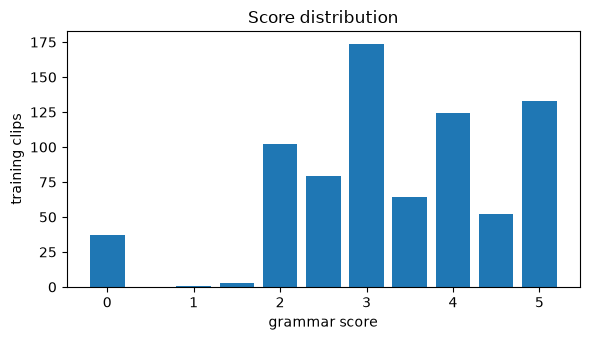

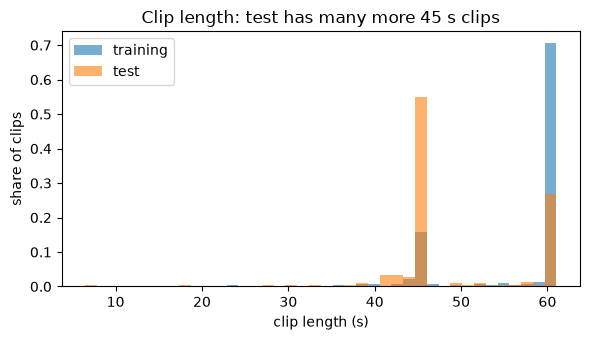

In [23]:
# ---- Clip lists ----
all_train = pd.read_csv("data/train.csv")         # 769 training clips: filename, label (the score)
test_clips = pd.read_csv("data/test.csv")         # 216 test clips
is_scored = (all_train["label"] > 0).to_numpy()   # True for the 732 clips scored 1-5, False for the 37 scored 0
y = all_train["label"].to_numpy()[is_scored]      # true scores of the 732 clips the models are trained on

# ---- Clip lengths (seconds) ----
all_train_seconds = np.array([sf.info("data/train/" + f).duration for f in all_train["filename"]])
test_seconds = np.array([sf.info("data/test/" + f).duration for f in test_clips["filename"]])
train_seconds = all_train_seconds[is_scored]             # lengths of the 732 clips scored 1-5
is_45s = (train_seconds > 44) & (train_seconds < 46)     # True for the clips of about 45 s
print("Training clips:", len(all_train), "  scored 0:", (~is_scored).sum(), "  scored 1-5:", is_scored.sum())
print("Test clips:", len(test_clips))
print(f"Clips of about 45 s: {is_45s.mean():.0%} of training, "
      f"{((test_seconds > 44) & (test_seconds < 46)).mean():.0%} of test")

# ---- Plots ----
# Number of training clips with each score
plt.figure(figsize=(6, 3.5))
counts = all_train["label"].value_counts().sort_index()
plt.bar(counts.index, counts.values, width=0.4)
plt.xlabel("grammar score")
plt.ylabel("training clips")
plt.title("Score distribution")
plt.tight_layout()
plt.savefig("output_submission/figures/score_distribution.png", dpi=120)   # also shown in the Approach section
plt.show()

# Clip lengths. The same 40 bars for training and test; each clip counts 1/(number of clips),
# so a bar's height is the share of clips with that length
bar_edges = np.linspace(min(train_seconds.min(), test_seconds.min()), max(train_seconds.max(), test_seconds.max()), 41)
plt.figure(figsize=(6, 3.5))
plt.hist(train_seconds, bins=bar_edges, alpha=0.6, weights=np.ones(len(train_seconds)) / len(train_seconds),
         label="training")
plt.hist(test_seconds, bins=bar_edges, alpha=0.6, weights=np.ones(len(test_seconds)) / len(test_seconds),
         label="test")
plt.xlabel("clip length (s)")
plt.ylabel("share of clips")
plt.title("Clip length: test has many more 45 s clips")
plt.legend()
plt.tight_layout()
plt.savefig("output_submission/figures/clip_lengths.png", dpi=120)   # also shown in the Approach section
plt.show()


Two things matter for the design:

* **The scores are uneven.** Most clips are scored 2-5 (most often 3: 174 clips), and only 4 clips are scored 1-1.5. With so few examples of the lowest scores, models tend to pull extreme clips towards the middle.
* **56% of test clips are about 45 s long, against 17% of training clips.** These clips are noisier. So every CV result is reported twice: on all clips and on the 45 s clips only.

## 2. Noise rule (score 0)

Listening to the 37 clips scored 0 shows they are background noise with no understandable speech. `src/snr.py` measures each clip's loudness in short frames: the noise level is the quietest frames, the signal-to-noise ratio (SNR) is loudest minus quietest. A clip gets 0 if its SNR is below 8 dB **and** its noise is louder than -28 dB (a quiet clean recording can also have a low SNR, so both are required).

**What this cell does:** runs `src/snr.py` (CPU, about 1 min) on the training and the test clips. For each clip, the script cuts the audio into 50 ms frames, measures the loudness of each frame in dB, and saves two numbers:
  * `noise_db`: the noise level = the loudness of the quiet frames (the 10th percentile: 10% of frames are quieter), i.e. the background noise.
  * `snr_db`: the signal-to-noise ratio = the loudness of the loud frames (the 95th percentile, i.e. speech) minus `noise_db`.


**Input:** the WAV files in `data/train/` and `data/test/`.

**Output:** `output_submission/snr_train.csv` and `output_submission/snr_test.csv`, with columns `filename`, `label`, `snr_db` and `noise_db`.

In [24]:
run_step(["src/snr.py"])           # training clips -> output_submission/snr_train.csv
run_step(["src/snr.py", "test"])   # test clips     -> output_submission/snr_test.csv

Running src/snr.py
Running src/snr.py test


**What this cell does:** applies the noise rule (score 0 if SNR < 8 dB and noise > -28 dB) to every training and test clip, and plots the training clips.

**Input:** `output_submission/snr_train.csv` and `output_submission/snr_test.csv`.

**Output:** how many clips the rule flags, whether they are the clips scored 0 (for training clips), and a plot of SNR against noise level for the training and the test clips, with the rule's limits (saved as `output_submission/figures/noise_rule.png`).

Training clips flagged: 37  of which scored 0: 37   Training clips scored 0 but missed: 0
Test clips flagged: 0


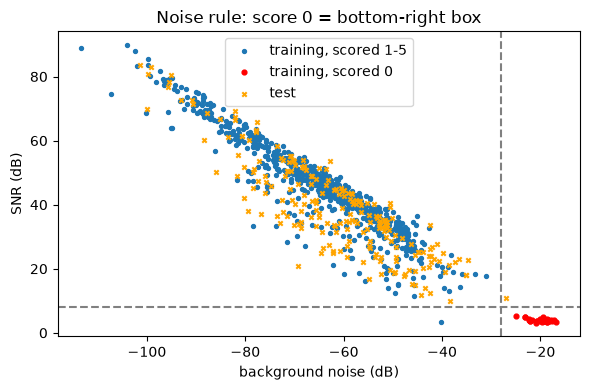

In [25]:
# SNR and noise level of every clip, in the order of the clip lists
snr_train = pd.read_csv("output_submission/snr_train.csv").set_index("filename").loc[all_train["filename"]]
snr_test = pd.read_csv("output_submission/snr_test.csv").set_index("filename").loc[test_clips["filename"]]

# Noise rule: True for the clips that get score 0 (low SNR and loud background noise)
flag_train = ((snr_train["snr_db"] < SNR_LIMIT) & (snr_train["noise_db"] > NOISE_LIMIT)).to_numpy()
flag_test = ((snr_test["snr_db"] < SNR_LIMIT) & (snr_test["noise_db"] > NOISE_LIMIT)).to_numpy()
is_zero = ~is_scored   # True for the training clips scored 0

print("Training clips flagged:", flag_train.sum(), " of which scored 0:", (flag_train & is_zero).sum(),
      "  Training clips scored 0 but missed:", (is_zero & ~flag_train).sum())
print("Test clips flagged:", flag_test.sum())

# Each clip is a point: background noise (x) against SNR (y). Training clips scored 1-5 are blue, training clips
# scored 0 are red, test clips (score unknown) are orange crosses.
# The dashed lines are the rule's limits: clips in the bottom-right box get score 0.
plt.figure(figsize=(6, 4))
plt.scatter(snr_train["noise_db"][~is_zero], snr_train["snr_db"][~is_zero], s=8, label="training, scored 1-5")
plt.scatter(snr_train["noise_db"][is_zero], snr_train["snr_db"][is_zero], s=12, color="red", label="training, scored 0")
plt.scatter(snr_test["noise_db"], snr_test["snr_db"], s=10, color="orange", marker="x", label="test")
plt.axhline(SNR_LIMIT, color="grey", linestyle="--")
plt.axvline(NOISE_LIMIT, color="grey", linestyle="--")
plt.xlabel("background noise (dB)")
plt.ylabel("SNR (dB)")
plt.title("Noise rule: score 0 = bottom-right box")
plt.legend()
plt.tight_layout()
plt.savefig("output_submission/figures/noise_rule.png", dpi=120)   # also shown in the Approach section
plt.show()

The rule finds all 37 score-0 training clips and no other clip, so on the training set these clips have zero error. In the test set, the rule flags no clip, so no test clip is predicted 0.

## 3. Transcripts

`src/transcribe.py` turns each clip into text. Its input is the clip's audio (a WAV file); its output is the clip's transcript. It uses **CrisperWhisper 2.0**, a Whisper model trained to write *exactly* what is said: fillers (`[UH]`, `[UM]`), repeated and cut-off words. Normal Whisper tidies speech into clean sentences, which hides the grammar errors we want to score.

* **Cutting at pauses.** The model hears at most 30 s at a time, so a longer clip is cut into pieces, at pauses so that no word is cut in two. The script measures the loudness of every 50 ms of audio. A pause is the quietest 200 ms stretch (4 slices of 50 ms in a row, so that a quiet moment inside a word is not taken for a pause). The first cut is made in the middle of the quietest 200 ms between 20 and 28 s from the start, the next one between 20 and 28 s after that cut, and so on until the rest of the clip is at most 30 s. Each piece is transcribed on its own and the texts are joined.
* **Loops.** Sometimes the model gets stuck and writes the same phrase over and over. Repeated text compresses very well, so a piece whose text shrinks more than 2.4 times when zipped is taken as a loop. That piece is cut again, at its quietest 200 ms between one third and two thirds of its length (for a 27 s piece: between 9 and 18 s), so that neither part is very short. Each part is transcribed on its own (cut again if it still loops, down to 2 s).

**Expensive step** (GPU, about 80 min). It runs only if `RUN_EXPENSIVE_STEPS = True`. If you skip it, its output is already saved in `output_submission/`: go to the next cell.

**What this cell does:** runs `src/transcribe.py` (described above) on the training and the test clips.

**Input:** the WAV files in `data/train/` and `data/test/`.

**Output:** `output_submission/transcripts_train.csv` and `output_submission/transcripts_test.csv` (filename, label, transcript), and one text file per clip in `output_submission/transcripts/`.

In [26]:
if RUN_EXPENSIVE_STEPS:
    run_step(["src/transcribe.py"])           # training clips
    run_step(["src/transcribe.py", "test"])   # test clips
else:
    print("Skipped: using the saved output_submission/transcripts_train.csv and transcripts_test.csv")

Skipped: using the saved output_submission/transcripts_train.csv and transcripts_test.csv


**What this cell does:** reads the transcripts, keeps the training clips scored 1-5 (the clips every model is trained on), and prints three example transcripts, chosen to show two things:
* the transcripts are word for word: fillers (`[UH]`, `[UM]`), repeated words (*play play play*), cut-off words (*play- playground*) and sound tags (`[breath]`) are kept;
* what changes with the score is the grammar, not the fillers: the score-2 clip has broken sentences and wrong verb forms (*is was*, *there are a lot kids*), the score-3 clip some errors (*These trees gives*), the score-5 clip fluent, mostly correct and longer sentences (*plantains that were fried with a special brown sauce on the side*), although it also has fillers. (About 80% of clips contain a filler, at every score.)

**Input:** `output_submission/transcripts_train.csv` and `output_submission/transcripts_test.csv`.

**Output:** the first 350 characters of the three example transcripts (scores 2, 3 and 5).

In [27]:
# Transcripts (filename, label, transcript), in the same order as data/train.csv and data/test.csv
train = pd.read_csv("output_submission/transcripts_train.csv")
train = train[train["label"] > 0].reset_index(drop=True)   # keep the 732 clips scored 1-5 (same order as y)
test = pd.read_csv("output_submission/transcripts_test.csv")

# Three example transcripts (first 350 characters), chosen by hand: scores 2, 3 and 5
for filename in ["audio_61.wav", "audio_436.wav", "audio_376.wav"]:
    example = train[train["filename"] == filename].iloc[0]
    print(f"Score {example['label']} ({filename}): {example['transcript'][:350]}...\n")

Score 2.0 (audio_61.wav): Well, when I was a child I remember I went to the kindergarten and I liked to playground. I remember there are a lot kids, a lot well the teacher [UM] just enjoy your life. You didn't think in other Those [UH] [breath] is was so good because you need just enjoy enjoy play play play with the with the land play with the cars [lipsmack] or [UM] play v...

Score 3.0 (audio_436.wav): The scene of a school play- playground, our playground looks like a very big playground having more more greenery trees. In which we students like to garden [UH] more trees to have a fresh air and all having a fresh oxygen. These [UH] in the playground These trees gives a very greenery view which will [UH] very pleasant to our minds and will give r...

Score 5.0 (audio_376.wav): My favorite place I visited before was [UH] Aguada, Puerto Rico [UM] I had to take two flights. I used Delta Airlines. Some of the local food was delicious, including the fruits were my favorite, but I also fou

**What this cell does:** counts three simple things in each training transcript and plots them against the score: fillers (`[UH]`, `[UM]`) per 100 words, repeated words (a word the same as the word before it, e.g. *the the*) per 100 words, and words per second (speaking speed). The title of each plot gives the correlation with the score.

**Input:** the transcripts and the clip lengths (from the cells above).

**Output:** three box plots (saved as `output_submission/figures/transcript_counts.png`), one box per score (the line in a box is the median; the box holds the middle half of the clips).

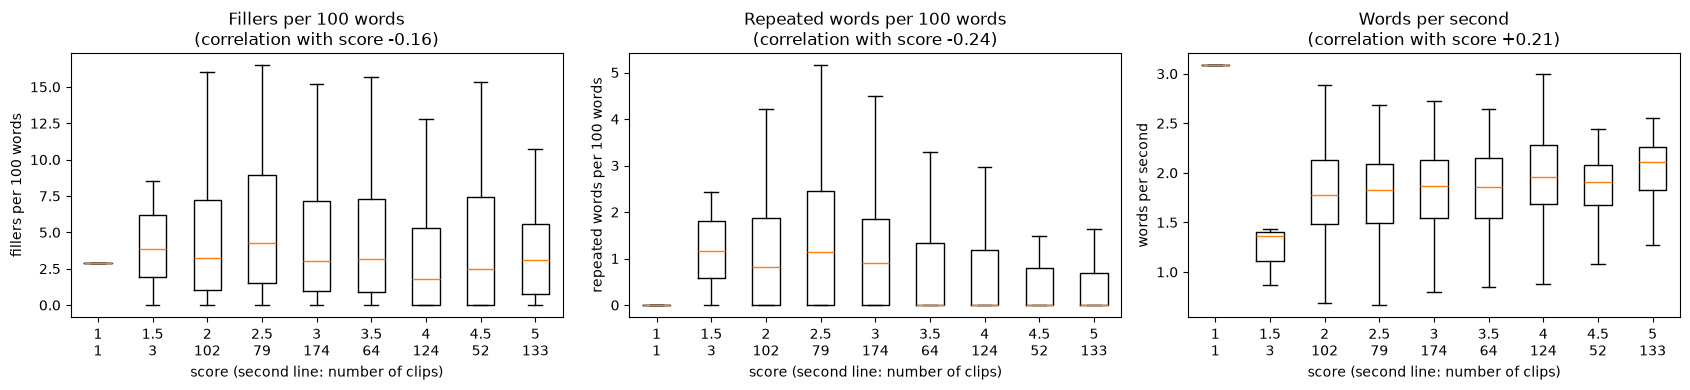

In [28]:
import re


def plain_words(text):
    """The spoken words of a transcript: tags like [UH] or [breath] removed, lower case, no punctuation.

    text: one transcript.
    Returns: the list of its words.
    """
    words = []
    for token in text.split():
        if not token.startswith("["):
            words.append(re.sub(r"[^a-z']", "", token.lower()))
    return words


fillers_per_100 = []
repeats_per_100 = []
words_per_second = []
for text, seconds in zip(train["transcript"].fillna(""), train_seconds):
    words = plain_words(text)
    fillers = text.count("[UH]") + text.count("[UM]")
    repeats = 0
    for i in range(1, len(words)):
        if words[i] != "" and words[i] == words[i - 1]:
            repeats = repeats + 1
    fillers_per_100.append(100 * fillers / len(words))
    repeats_per_100.append(100 * repeats / len(words))
    words_per_second.append(len(words) / seconds)

# One box plot per count: one box per score
levels = sorted(set(y))
clips_per_score = [(y == level).sum() for level in levels]
counts = {"Fillers per 100 words": np.array(fillers_per_100),
          "Repeated words per 100 words": np.array(repeats_per_100),
          "Words per second": np.array(words_per_second)}
figure, axes = plt.subplots(1, 3, figsize=(17, 4))
for axis, (title, values) in zip(axes, counts.items()):
    axis.boxplot([values[y == level] for level in levels], showfliers=False)   # outliers not drawn, to keep the scale readable
    axis.set_xticks(range(1, len(levels) + 1))
    axis.set_xticklabels([f"{level:g}\n{n}" for level, n in zip(levels, clips_per_score)])
    axis.set_xlabel("score (second line: number of clips)")
    axis.set_ylabel(title.lower())
    axis.set_title(f"{title}\n(correlation with score {np.corrcoef(values, y)[0, 1]:+.2f})")
plt.tight_layout()
plt.savefig("output_submission/figures/transcript_counts.png", dpi=120)   # also shown in the Approach section
plt.show()

* **Fillers barely change with the score** (correlation -0.16): the score is about grammar, not about hesitation sounds.
* **Repeated words and speaking speed go with the score, but weakly** (-0.24 and +0.21): the boxes of different scores overlap heavily. Clips scored 3.5 or more mostly have no repeated word at all (median 0), clips scored 3 or less mostly have some. (Scores 1 and 1.5 have only 1 and 3 clips, so their boxes say little.)
* So simple counts cannot tell the scores apart. The grammar has to be judged from the whole transcript, by language models that read it: frozen DeBERTa with Ridge reaches a CV Pearson correlation of 0.82 and the fine-tuned models 0.83 (sections 5-6).

## 4. Cross-validation by speaker

Many speakers recorded several clips. With random folds, a model can recognise a voice it saw in training instead of judging grammar, and CV looks better than it is. Test clips come from new speakers, so `src/speakers.py` groups the clips by voice (as described in step 2 in the approach), and every speaker's clips stay in one fold.

**Expensive step** (GPU, about 3 min). It runs only if `RUN_EXPENSIVE_STEPS = True`. If you skip it, its output is already saved in `output_submission/`: go to the next cell.

**What this cell does:** runs `src/speakers.py`, which finds which training clips come from the same speaker. A speaker-recognition model (WavLM-base-plus-sv) turns each clip into a voice fingerprint of 512 numbers. The average fingerprint of all clips is subtracted from each one, so that what all clips share (same microphone, same kind of recording) does not make different speakers look alike. Then the clips are grouped bottom-up: the two most similar groups are joined, again and again, while their average cosine similarity is at least 0.85. Each final group is one speaker.

**Input:** the WAV files of the 732 training clips scored 1-5 (listed in `output_submission/transcripts_train.csv`).

**Output:** `output_submission/speaker_groups.csv` (filename, speaker number).

In [29]:
if RUN_EXPENSIVE_STEPS:
    run_step(["src/speakers.py"])
else:
    print("Skipped: using the saved output_submission/speaker_groups.csv")

Skipped: using the saved output_submission/speaker_groups.csv


**What this cell does:** makes the 5 cross-validation folds so that all clips of one speaker are in the same fold, and defines two functions, `cv_rmse` and `cv_pearson`, that report CV results: the average RMSE and the average Pearson correlation, averaged over the 5 validation folds (for the RMSE, also their standard deviation).

**Input:** `output_submission/speaker_groups.csv`.

**Output:** the number of speakers and of clips in each fold.

In [30]:
# Speaker number of each training clip, in the order of the training clips
speakers = by_filename("output_submission/speaker_groups.csv", "speaker", train["filename"])

# 5 folds; all clips of one speaker go into the same fold.
# folds[k] = (positions of the training clips, positions of the validation clips) of fold k.
# src/finetune_text.py makes the same folds in the same way.
folds = list(GroupKFold(n_splits=N_FOLDS).split(train, groups=speakers))
print("Speakers:", len(set(speakers)), " clips per fold:", [len(validation) for _, validation in folds])


def cv_rmse(predictions, keep=None):
    """CV RMSE: the RMSE on each of the 5 validation folds, then the mean and the standard deviation of the 5 RMSEs.

    predictions: one predicted score for each of the 732 training clips (in the order of y), where each clip is
                 predicted by the fold model that did NOT train on it. The 5 fold models together predict every clip
                 once, so one array holds the predictions of all 5 folds; the function splits it back into the folds.
    keep (optional): True/False for each of the 732 clips; only the clips marked True are used,
                 e.g. keep=is_45s uses only the 45 s clips of each fold.
    Returns: (mean of the 5 fold RMSEs, standard deviation of the 5 fold RMSEs).
    """
    fold_rmses = []
    for _, validation in folds:
        if keep is not None:
            validation = validation[keep[validation]]
        fold_rmses.append(rmse(y[validation], predictions[validation]))
    return np.mean(fold_rmses), np.std(fold_rmses)


def cv_pearson(predictions):
    """CV Pearson: the Pearson correlation between true and predicted scores on each of the 5 validation folds,
    averaged over the folds.

    predictions: as in cv_rmse (one cross-validated prediction for each of the 732 training clips).
    Returns: the mean of the 5 fold correlations.
    """
    return np.mean([np.corrcoef(y[validation], predictions[validation])[0, 1] for _, validation in folds])

Speakers: 301  clips per fold: [147, 147, 146, 146, 146]


## 5. Frozen models + Ridge (5 parts)

Five of the seven parts of the blend use pretrained models as they are (frozen: not trained here). Each clip is turned into a vector of numbers (an embedding), and a Ridge regression predicts the score from it. This takes three steps, two in scripts (used here in the notebook) and one coded in this notebook:

1. **GED error embedding**: `src/error_embedding.py`. Input: the transcripts. Output: one vector of 1024 numbers per clip. GED-ELECTRA, a grammar error detector, gives each word of the transcript a probability of being wrong. The error embedding is the average of the words' vectors from its last layer, weighted by those probabilities: words that look wrong count most, so the vector describes *which kind* of errors the speaker makes rather than the topic.
2. **Frozen embeddings**: `src/frozen_embeddings.py`. Input: the audio and the transcripts. Output: one vector per clip for each of 5 models. The audio goes through 4 speech-recognition encoders (Whisper, Phi-4 audio, Parakeet-CTC, Parakeet-TDT), which describe the sounds and words spoken, including hesitations. The transcript goes through the text model DeBERTa-v3-large. From each model, the script takes the output of one layer (the layer with the best CV, see step 4 of the approach), which is one vector per short slice of audio or per text token, and averages it over the whole clip: 1280 numbers for Whisper, 1024 for the others. A clip too long for a model is cut into pieces (30 s for Whisper, 40 s for Phi-4) and the average is taken over all pieces.
3. **Ridge**: fitted in this notebook (the last cell of this section). Each audio model's vector is one part; DeBERTa's vector and the GED error embedding are joined side by side (2048 numbers) into the fifth part. For each part, Ridge standardises each number, then fits a linear regression with an L2 penalty, which RidgeCV chooses by leave-one-out CV on the clips it is fitted on. Predictions are clipped to 1-5.

**Expensive step** (GPU, about 1 min). It runs only if `RUN_EXPENSIVE_STEPS = True`. If you skip it, its output is already saved in `output_submission/`: go to the next cell.

**What this cell does:** runs `src/error_embedding.py` (step 1 above) on the training and the test transcripts.

**Input:** `output_submission/transcripts_train.csv` and `output_submission/transcripts_test.csv`.

**Output:** `output_submission/embeddings/ged_error_embedding_train.npy` (732 clips x 1024 numbers) and `output_submission/embeddings/ged_error_embedding_test.npy` (216 clips x 1024 numbers).

In [31]:
if RUN_EXPENSIVE_STEPS:
    run_step(["src/error_embedding.py"])
else:
    print("Skipped: using the saved output_submission/embeddings/ged_error_embedding_*.npy")

Skipped: using the saved output_submission/embeddings/ged_error_embedding_*.npy


**Expensive step** (GPU, about 17 min). It runs only if `RUN_EXPENSIVE_STEPS = True`. If you skip it, its output is already saved in `output_submission/`: go to the next cell.

**What this cell does:** runs `src/frozen_embeddings.py` (step 2 above) on the training and the test clips.

**Input:** the WAV files in `data/train/` and `data/test/`, and text files in `output_submission/transcripts_train.csv` and `output_submission/transcripts_test.csv`.

**Output:** in `output_submission/embeddings/<model>_train.npy` (732 clips) and `output_submission/embeddings/<model>_test.npy` (216 clips) for whisper_l32, phi4_audio_l23, parakeet_ctc_l36, parakeet_tdt_l20 and deberta_v3_large_l21 (the number = the layer used).

In [32]:
if RUN_EXPENSIVE_STEPS:
    run_step(["src/frozen_embeddings.py"])
else:
    print("Skipped: using the saved output_submission/embeddings/*.npy")

Skipped: using the saved output_submission/embeddings/*.npy


**What this cell does:** fits the Ridge models (step 3 above). Each of the 5 parts is fitted in two ways, for two purposes:
* **One Ridge per fold, to measure the part (CV).** Each is fitted on 4 folds and predicts the clips of the 5th, which it has not seen. Together the 5 fold models predict every training clip once, as if it were a new clip, which gives the CV RMSE: an estimate of how well the part does on new speakers. These models are used only for this measurement.
* **One Ridge on all 732 training clips, to make the predictions (the final model).** More training clips give a better model, so the final model uses them all. It predicts the test clips, and its error on the training clips is the training RMSE. Its error on new clips cannot be measured directly (no clip is left over); the CV RMSE of the fold models, trained the same way on slightly fewer clips, estimates it.

**Input:** the embeddings in `output_submission/embeddings/` (from the two cells above), the true scores `y` (section 1, read from `data/train.csv`) and the speaker folds `folds` (section 4, made from `output_submission/speaker_groups.csv`).

**Output:** for each part, the size of its vector and the Ridge penalty chosen on all 732 clips.

In [33]:
# Each frozen part: name -> its embedding files (DeBERTa and the GED error embedding are joined side by side)
FROZEN_PARTS = {"Whisper L32": ["whisper_l32"],
                "Phi-4 audio L23": ["phi4_audio_l23"],
                "Parakeet-CTC L36": ["parakeet_ctc_l36"],
                "Parakeet-TDT L20": ["parakeet_tdt_l20"],
                "DeBERTa-v3-large L21 + GED errors": ["deberta_v3_large_l21", "ged_error_embedding"]}


def make_ridge():
    """Standardise each number of the vector, then Ridge; RidgeCV picks the penalty from ALPHAS by leave-one-out CV."""
    return make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS))


cv_predictions = {}     # part -> each training clip predicted by the fold model that did not train on it
train_predictions = {}  # part -> each training clip predicted by the final model (fitted on all 732 clips)
test_predictions = {}   # part -> each test clip predicted by the final model
for name, files in FROZEN_PARTS.items():
    # The part's vectors: one row per clip
    X_train = np.hstack([np.load(f"{EMBEDDINGS}/{f}_train.npy") for f in files])
    X_test = np.hstack([np.load(f"{EMBEDDINGS}/{f}_test.npy") for f in files])

    # Cross-validation: fit on 4 folds, predict the 5th. Predictions are clipped to the score range 1-5.
    cv = np.zeros(len(y))
    for train_index, validation_index in folds:
        model = make_ridge().fit(X_train[train_index], y[train_index])
        cv[validation_index] = np.clip(model.predict(X_train[validation_index]), 1, 5)
    cv_predictions[name] = cv

    # Final model: fitted on all 732 training clips
    final_model = make_ridge().fit(X_train, y)
    train_predictions[name] = np.clip(final_model.predict(X_train), 1, 5)
    test_predictions[name] = np.clip(final_model.predict(X_test), 1, 5)
    # final_model[-1] is the RidgeCV step; alpha_ is the penalty it chose
    print(f"{name:35s} {X_train.shape[1]} numbers per clip, penalty {final_model[-1].alpha_:g}")

Whisper L32                         1280 numbers per clip, penalty 1000
Phi-4 audio L23                     1024 numbers per clip, penalty 1000
Parakeet-CTC L36                    1024 numbers per clip, penalty 316.228
Parakeet-TDT L20                    1024 numbers per clip, penalty 1000
DeBERTa-v3-large L21 + GED errors   2048 numbers per clip, penalty 1000


## 6. Fine-tuned text models (2 parts)

`src/finetune_text.py` fine-tunes a whole text model on the transcripts: model → average of token vectors → one linear output (the score). Its input is the transcripts (`output_submission/transcripts_train.csv` and `transcripts_test.csv`) and the speaker groups (`output_submission/speaker_groups.csv`, section 4). Its output is 5 files in `output_submission/`, named `finetune_<model>_...` (`<model>` = `deberta_v3_large` or `deberta_v2_xlarge`):
* `_results.csv`: CV RMSE and Pearson (mean and standard deviation over the 5 folds) and training RMSE, after each epoch;
* `_epochs.csv`: training loss and validation RMSE for each fold and epoch;
* `_cv_predictions.csv`: each training clip predicted by the fold model that did not train on it, at the chosen epoch;
* `_train_predictions.csv`: each training clip predicted by the average of the 4 fold models that trained on it, at the chosen epoch;
* `_test_predictions.csv`: each test clip predicted by the average of the 5 fold models, at the chosen epoch.

The model is chosen with the `--model` option, so the script is run twice, once per model:
* `python src/finetune_text.py` (no option): **DeBERTa-v3-large**, all 24 layers (434M weights);
* `python src/finetune_text.py --model=deberta_v2_xlarge`: **DeBERTa-v2-xlarge**, cut after layer 12 of 24 (its best layer when frozen), with its word embeddings frozen so that training fits in 16 GB of GPU memory.

Both models are trained the same way:

* **Training**: 6 epochs, batch 8, AdamW (learning rate 1e-5 for the model, 1e-3 for the output, weight decay 0.01), 10% warm-up then linear decay, MSE loss on standardised scores, no dropout.
* **Epoch choice**: the same 5 speaker folds; after every epoch each fold model predicts its validation clips. The epoch with the lowest mean CV RMSE is used (v3-large: 4, v2-xlarge: 3).
* **Test predictions**: the average of the 5 fold models at that epoch. Unlike Ridge (section 5), no final model is trained on all clips. Fine-tuning is noisy: two runs that differ only in the random seed give clearly different models. Averaging 5 models cancels much of this noise. Ridge has no such noise (the same clips always give the same model), so one final Ridge fitted on all clips is enough.

**Expensive step** (GPU, about 9 min). It runs only if `RUN_EXPENSIVE_STEPS = True`. If you skip it, its output is already saved in `output_submission/`: go to the next cell.

**What this cell does:** runs `src/finetune_text.py`, which fine-tunes DeBERTa-v3-large on the transcripts as described above. It trains one model per speaker fold (on the other 4 folds) for 6 epochs. After every epoch, each fold model predicts its validation clips, the clips it trained on, and the test clips.

**Input:** `output_submission/transcripts_train.csv`, `output_submission/transcripts_test.csv` and `output_submission/speaker_groups.csv`.

**Output:** the 5 files described above, named `output_submission/finetune_deberta_v3_large_*.csv`.

In [34]:
if RUN_EXPENSIVE_STEPS:
    run_step(["src/finetune_text.py"])
else:
    print("Skipped: using the saved output_submission/finetune_deberta_v3_large_*.csv")

Skipped: using the saved output_submission/finetune_deberta_v3_large_*.csv


**Expensive step** (GPU, about 8 min). It runs only if `RUN_EXPENSIVE_STEPS = True`. If you skip it, its output is already saved in `output_submission/`: go to the next cell.

**What this cell does:** runs `src/finetune_text.py --model=deberta_v2_xlarge` (DeBERTa-v2-xlarge, see above) in the same way.

**Input:** the same files as the cell above.

**Output:** the same files, named `output_submission/finetune_deberta_v2_xlarge_*.csv`.

In [35]:
if RUN_EXPENSIVE_STEPS:
    run_step(["src/finetune_text.py", "--model=deberta_v2_xlarge"])
else:
    print("Skipped: using the saved output_submission/finetune_deberta_v2_xlarge_*.csv")

Skipped: using the saved output_submission/finetune_deberta_v2_xlarge_*.csv


**What this cell does:** plots, for each fine-tuned model, how its RMSE changes during training: after each epoch, the CV RMSE (the average of the each of the 5 fold model's error on the validation clips) and the training RMSE (the average of each of the 5 fold model's error on the 4 folds it trained on). A dashed line marks the epoch the script chose (the one with the lowest CV RMSE). The plot shows when the models start to memorise the training clips: the training RMSE keeps falling, while the CV RMSE stops improving.

**Input:** `output_submission/finetune_deberta_v3_large_results.csv` and `output_submission/finetune_deberta_v2_xlarge_results.csv` (section 6 cells above).

**Output:** one plot per model (saved as `output_submission/figures/finetune_epochs.png`).

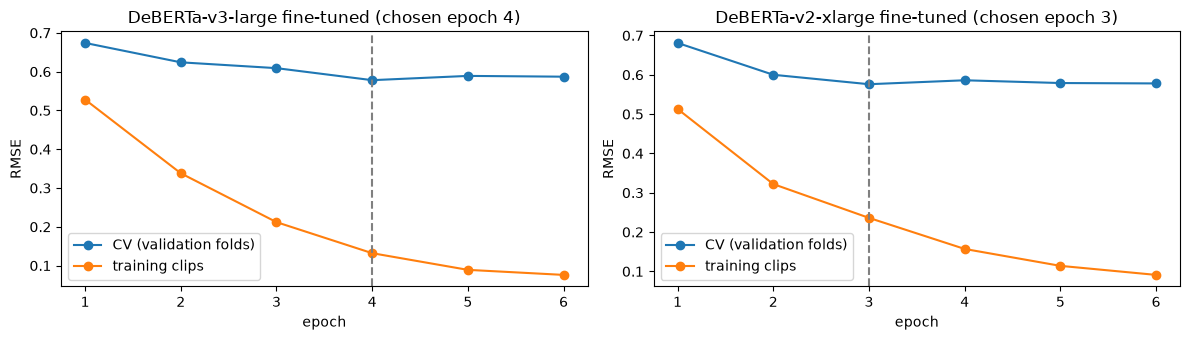

In [36]:
# Each fine-tuned part: name -> start of its output file names (written by src/finetune_text.py)
FINETUNED_PARTS = {"DeBERTa-v3-large fine-tuned": "finetune_deberta_v3_large",
                   "DeBERTa-v2-xlarge fine-tuned": "finetune_deberta_v2_xlarge"}

figure, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for axis, (name, run) in zip(axes, FINETUNED_PARTS.items()):
    # CV RMSE (mean of the 5 folds) and training RMSE after each epoch
    epochs = pd.read_csv(f"output_submission/{run}_results.csv")
    # The epoch the script chose: the one with the lowest CV RMSE (found again here only to mark it on the plot)
    chosen_epoch = int(epochs.loc[epochs["cv_rmse_mean"].idxmin(), "epoch"])

    axis.plot(epochs["epoch"], epochs["cv_rmse_mean"], marker="o", label="CV (validation folds)")
    axis.plot(epochs["epoch"], epochs["train_rmse"], marker="o", label="training clips")
    axis.axvline(chosen_epoch, color="grey", linestyle="--")
    axis.set_xlabel("epoch")
    axis.set_ylabel("RMSE")
    axis.set_title(f"{name} (chosen epoch {chosen_epoch})")
    axis.legend()
plt.tight_layout()
plt.savefig("output_submission/figures/finetune_epochs.png", dpi=120)   # also shown in the Approach section
plt.show()

The models keep improving on the training clips long after CV stops improving: they memorise the training clips (training RMSE 0.1-0.2 against CV 0.58). 

**What this cell does:** reads the predictions of the two fine-tuned models at the chosen epoch, so that they can join the 5 frozen parts in the blend (section 7).

**Input:** `output_submission/finetune_<model>_cv_predictions.csv`, `_train_predictions.csv` and `_test_predictions.csv` for both models (section 6 cells above).

**Output:** nothing printed.

In [37]:
# Predictions at the chosen epoch, in the order of the training / test clips. They are added to the predictions of
# the 5 frozen parts (section 5): cv_predictions, train_predictions and test_predictions now hold all 7 parts.
for name, run in FINETUNED_PARTS.items():
    # CV: each training clip predicted by the fold model that did not train on it
    cv_predictions[name] = by_filename(f"output_submission/{run}_cv_predictions.csv", "prediction", train["filename"])
    # Training: no model was fine-tuned on all clips, so a clip's training prediction is the average of the
    # 4 fold models that trained on it
    train_predictions[name] = by_filename(f"output_submission/{run}_train_predictions.csv", "average", train["filename"])
    # Test: the average of the 5 fold models
    test_predictions[name] = by_filename(f"output_submission/{run}_test_predictions.csv", "average", test["filename"])

## 7. The blend and the training RMSE

Final score = weighted average of the 7 parts: 1/8 for each audio part, 1/6 for each text part (audio part and text part each weighed half; equal weights within each half. Not fitted to avoid overfitting the weights).

**What this cell does:** averages the 7 parts with fixed weights and makes a table of every part and of the blend.

**Input:** the CV and training predictions of the 7 parts, `cv_predictions` and `train_predictions` (the 5 frozen parts from section 5, the 2 fine-tuned parts from the last cell of section 6); the true scores `y` and the 45 s clips `is_45s` (section 1); the speaker folds, used by `cv_rmse` and `cv_pearson` (section 4).

**Output:** a table with the training RMSE, the CV RMSE (all clips and 45 s clips; mean and standard deviation over the 5 validation folds) and the CV Pearson (mean over the 5 folds) of each part and of the blend.

No model was fine-tuned on all training clips, so for the two fine-tuned parts the training RMSE uses each clip's prediction by the average of the 4 fold models that trained on it (section 6). This is lower than the training RMSE in the epoch plot of section 6, which scores each fold model on its own: averaging models cancels part of their errors (DeBERTa-v3-large at epoch 4: 0.094 here, 0.132 in the plot).

In [38]:
# Fixed weights: half to the 4 audio parts (1/8 each), half to the 3 text parts (1/6 each)
WEIGHTS = {"Whisper L32": 1 / 8, "Phi-4 audio L23": 1 / 8, "Parakeet-CTC L36": 1 / 8, "Parakeet-TDT L20": 1 / 8,
           "DeBERTa-v3-large L21 + GED errors": 1 / 6,
           "DeBERTa-v3-large fine-tuned": 1 / 6, "DeBERTa-v2-xlarge fine-tuned": 1 / 6}

# Blend = weighted average of the parts' predictions (CV and training; the test blend is made in section 8)
blend_cv = np.zeros(len(y))
blend_train = np.zeros(len(y))
for name, weight in WEIGHTS.items():
    blend_cv = blend_cv + weight * cv_predictions[name]
    blend_train = blend_train + weight * train_predictions[name]

# Table: one row per part, and one for the blend
rows = []
names_and_weights = list(WEIGHTS.items()) + [("BLEND", 1.0)]
all_cv_predictions = dict(cv_predictions, BLEND=blend_cv)            # the parts and the blend together
all_train_predictions = dict(train_predictions, BLEND=blend_train)
for name, weight in names_and_weights:
    cv_mean, cv_std = cv_rmse(all_cv_predictions[name])                       # all validation clips of each fold
    cv_45s_mean, cv_45s_std = cv_rmse(all_cv_predictions[name], keep=is_45s)  # only the 45 s clips of each fold
    rows.append([name, round(weight, 3), rmse(y, all_train_predictions[name]), cv_mean, cv_std,
                 cv_45s_mean, cv_45s_std, cv_pearson(all_cv_predictions[name])])
results = pd.DataFrame(rows, columns=["part", "weight", "training RMSE", "CV RMSE", "CV RMSE std",
                                      "CV RMSE (45 s clips)", "std (45 s)", "CV Pearson"])
results.round(3)

,part,weight,training RMSE,CV RMSE,CV RMSE std,CV RMSE (45 s clips),std (45 s),CV Pearson
0,Whisper L32,0.125,0.421,0.554,0.024,0.580,0.062,0.840
1,Phi-4 audio L23,0.125,0.472,0.579,0.020,0.595,0.034,0.825
2,Parakeet-CTC L36,0.125,0.445,0.556,0.016,0.613,0.024,0.838
3,Parakeet-TDT L20,0.125,0.461,0.575,0.015,0.572,0.025,0.829
4,DeBERTa-v3-large L21 + GED errors,0.167,0.367,0.583,0.027,0.590,0.027,0.824
5,DeBERTa-v3-large fine-tuned,0.167,0.094,0.578,0.025,0.585,0.074,0.826
6,DeBERTa-v2-xlarge fine-tuned,0.167,0.180,0.576,0.025,0.543,0.044,0.829
7,BLEND,1.000,0.289,0.516,0.014,0.522,0.033,0.868


**What this cell does:** computes the training RMSE of the final model, and the CV RMSE.

**Input:** the blend's training and CV predictions `blend_train` and `blend_cv` (previous cell); the true scores `y` and the scores of all 769 training clips `all_train` (section 1, from `data/train.csv`); the noise-rule flags of the training clips `flag_train` (section 2).

**Output:** the training RMSE on the 732 clips scored 1-5 and on all 769 clips (the noise rule gives the 37 score-0 clips 0), and the CV RMSE (mean and standard deviation over the 5 validation folds).

In [39]:
# Prediction of all 769 training clips: the blend for the clips scored 1-5, and 0 for the clips flagged by
# the noise rule (these are exactly the 37 clips scored 0, so they have no error)
full_train_prediction = np.zeros(len(all_train))
full_train_prediction[is_scored] = blend_train
full_train_prediction[flag_train] = 0
print(f"TRAINING RMSE (final model, 732 clips scored 1-5):     {rmse(y, blend_train):.3f}")
print(f"TRAINING RMSE (all 769 clips, with the noise rule):    {rmse(all_train['label'].to_numpy(), full_train_prediction):.3f}")
cv_mean, cv_std = cv_rmse(blend_cv)
print(f"CV RMSE (speaker-grouped, mean of the 5 folds):        {cv_mean:.3f} +- {cv_std:.3f}")

TRAINING RMSE (final model, 732 clips scored 1-5):     0.289
TRAINING RMSE (all 769 clips, with the noise rule):    0.281
CV RMSE (speaker-grouped, mean of the 5 folds):        0.516 +- 0.014


* **The blend beats every part** in CV (0.516 against 0.554-0.583), because the parts' errors are only partly correlated (plot below).
* **Training RMSE (0.289) is much lower than CV RMSE (0.516).** Part of this is memorisation (mainly the fine-tuned models), and part is probably noise in the labels themselves (a human score on a 0.5-point scale), which no model can predict.
* The leaderboard (0.3255) is much better than CV (0.516): the test set differs from the training set (56% 45 s clips, no clip flagged as noise); its labels may be cleaner or less extreme. CV was used only to compare models.

**What this cell does:** draws two figures (three plots) of the CV predictions (each training clip predicted by a model that did not train on it). CV predictions are used instead of training predictions (a training clip predicted by a model that trained on it), because they show how the blend does on clips it has not seen, like the test clips:
* **First figure: do the parts make the same mistakes?** A part's error on a clip is its CV prediction minus the true score (positive = predicted too high). Each part thus has 732 errors, one per training clip. Each square is the correlation between the errors of two parts over the 732 clips. Near 1: the two parts are wrong on the same clips, in the same direction, so averaging them cancels little. Lower: they make different mistakes, so averaging them cancels part of the errors. (The diagonal is a part with itself: 1.)
* **Second figure, left: is the blend biased for some scores?** A single RMSE hides *where* the blend is wrong. This plot shows whether clips of a given score are predicted too high or too low on the whole. Each dot is a training clip: x = its true score, y = the blend's CV prediction. The true scores are only 1, 1.5, ..., 5, so each dot is moved left or right by a small random amount (at most 0.1) to keep the dots of one score apart. Dots on the dashed line are predicted exactly; dots above it are predicted too high, below it too low.
* **Second figure, right: which scores have the largest errors?** It puts a number on what the left plot shows: how large the blend's error is for the clips of each score, i.e. which kinds of speakers the blend judges worst. (A score with a large error but few clips adds little to the overall RMSE; the number of clips per score is in section 1.) For each true score (e.g. 2.0), take all training clips with that score and compute the RMSE between their true score and their blend CV prediction. This is one RMSE over the clips of all 5 folds together, not the mean of 5 fold RMSEs used for the CV RMSE elsewhere: some scores have only a few clips, too few to split into 5 folds.

**Input:** the CV predictions of the parts `cv_predictions` (sections 5 and 6) and of the blend `blend_cv` (the blend cell above); the true scores `y` (section 1).

**Output:** two figures, also saved in `output_submission/figures/` (`error_correlation.png`, `blend_errors.png`).

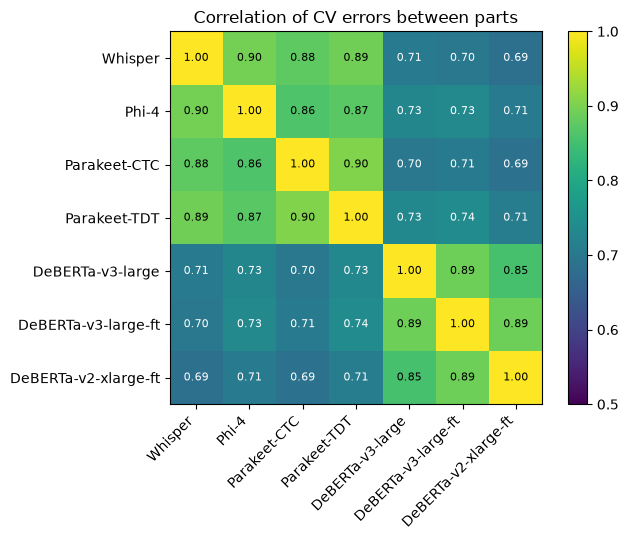

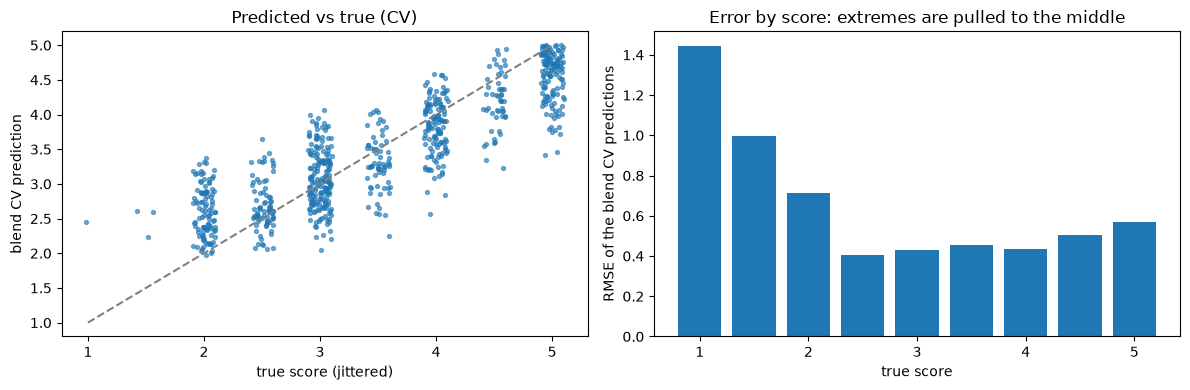

In [40]:
# Correlation between the parts' CV errors (prediction - true score). Lower = the parts make different mistakes.
names = list(WEIGHTS)
errors = np.array([cv_predictions[name] - y for name in names])
error_correlation = np.corrcoef(errors)
short_names = [name.split(" ")[0] + ("-ft" if "fine" in name else "") for name in names]   # e.g. "DeBERTa-v3-large-ft"

plt.figure(figsize=(7, 5.5))
plt.imshow(error_correlation, vmin=0.5, vmax=1, cmap="viridis")
plt.xticks(range(len(names)), short_names, rotation=45, ha="right")
plt.yticks(range(len(names)), short_names)
for i in range(len(names)):            # write each correlation in its square
    for j in range(len(names)):
        text_color = "black" if error_correlation[i, j] > 0.8 else "white"   # readable on light and dark squares
        plt.text(j, i, f"{error_correlation[i, j]:.2f}", ha="center", va="center", fontsize=8, color=text_color)
plt.title("Correlation of CV errors between parts")
plt.colorbar()
plt.tight_layout()
plt.savefig("output_submission/figures/error_correlation.png", dpi=120)   # also shown in the Approach section
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: blend CV prediction against the true score. A small random shift (jitter) on x keeps the points
# of one score apart; the dashed line is a perfect prediction.
axes[0].scatter(y + np.random.default_rng(0).uniform(-0.1, 0.1, len(y)), blend_cv, s=8, alpha=0.6)
axes[0].plot([1, 5], [1, 5], color="grey", linestyle="--")
axes[0].set_xlabel("true score (jittered)")
axes[0].set_ylabel("blend CV prediction")
axes[0].set_title("Predicted vs true (CV)")

# Right: for each true score, the RMSE of the blend's CV predictions of the clips with that score
# (one RMSE over all folds together, not the mean of 5 fold RMSEs: some scores have few clips)
levels = sorted(set(y))
axes[1].bar(levels, [rmse(y[y == level], blend_cv[y == level]) for level in levels], width=0.4)
axes[1].set_xlabel("true score")
axes[1].set_ylabel("RMSE of the blend CV predictions")
axes[1].set_title("Error by score: extremes are pulled to the middle")
plt.tight_layout()
plt.savefig("output_submission/figures/blend_errors.png", dpi=120)   # also shown in the Approach section
plt.show()


* **First figure (do the parts make the same mistakes?):** the 4 audio parts make similar mistakes (error correlation 0.86-0.90 between any two of them), and so do the 3 text parts (0.85-0.89), but an audio part and a text part much less (0.69-0.74). So the blend gains mostly from mixing audio and text parts; one more part like the ones already in a group would add little.
* **Second figure, left (is the blend biased for some scores?):** yes, it pulls its predictions towards the middle. Low scores are predicted too high and high scores too low: on average, clips scored 2.0 get 2.61 and clips scored 5.0 get 4.55, while clips scored 3.0 get 3.08 (nearly right). This is common for regression on scores that pile up in the middle (section 1).
* **Second figure, right (which scores have the largest errors?):** the extremes. RMSE 0.71 for clips scored 2.0 and 0.57 for 5.0, against 0.41-0.50 for the scores between (scores 1 and 1.5 have only 1 and 3 clips). Clips scored 2.0 matter most: they are many (102) and have the largest error, mostly because they are predicted too high (by 0.61 on average).

## 8. Submission

**What this cell does:** averages the 7 parts' test predictions with the same fixed weights as in section 7 (the test blend), and writes the submission: the blend's predictions on the test clips, with 0 for the test clips flagged by the noise rule.

**Input:** the test predictions of the 7 parts, `test_predictions`: for the 5 frozen parts, computed in the last cell of section 5 (each final Ridge, fitted on all 732 training clips, predicts the test clips from the test embeddings `output_submission/embeddings/<model>_test.npy`); for the 2 fine-tuned parts, read in the last cell of section 6 from `output_submission/finetune_<model>_test_predictions.csv`; the weights `WEIGHTS` (section 7); the noise-rule flags of the test clips `flag_test` (section 2).

**Output:** `output_submission/submission_blend_ridge.csv` (filename, label) and a summary of its scores.

In [41]:
# Test blend: the same weighted average of the 7 parts (weights WEIGHTS, section 7) on the test clips
blend_test = np.zeros(len(test))
for name, weight in WEIGHTS.items():
    blend_test = blend_test + weight * test_predictions[name]

# Submission: the test blend; test clips flagged by the noise rule get 0
submission = pd.DataFrame({"filename": test["filename"], "label": blend_test})
submission.loc[flag_test, "label"] = 0
submission.to_csv("output_submission/submission_blend_ridge.csv", index=False)
print("Test clips set to 0 by the noise rule:", flag_test.sum())
print(submission.describe().round(3))   # count, mean, standard deviation, min, quartiles and max of the scores

Test clips set to 0 by the noise rule: 0
         label
count  216.000
mean     3.288
std      0.781
min      1.861
25%      2.661
50%      3.180
75%      3.713
max      4.989


## 9. Summary

* **Final model**: 4 frozen speech encoders + 1 frozen text encoder (each with Ridge) and 2 fine-tuned DeBERTa models, averaged half audio, half text; a noise rule gives 0 to clips with no speech.
* **Training RMSE 0.289**, speaker-grouped CV RMSE 0.516, leaderboard 0.3255.
* **What mattered most**: verbatim transcripts, speaker-grouped CV, and combining audio and text models that make different mistakes. Bigger or more heavily tuned single models gave little.